In [1]:
#Import Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
#Buat Dataset Acak
np.random.seed(42)
data = {
    'CustomerID': range(1,201),
    'Age': np.random.randint(18,60,200),
    'Monthly Orders': np.random.randint(1,30,200),
    'Avg Spend (Rp)': np.random.randint(50000,2000000,200),
    'Favorite Category': np.random.choice(
        ['Fashion','Electronics','Groceries','Beauty','Books','Sports','Home Decor'],
        200
    )
}

In [3]:
#Tampilkan Dataset
df = pd.DataFrame(data)
df

,CustomerID,Age,Monthly Orders,Avg Spend (Rp),Favorite Category
0,1,56,6,714076,Electronics
1,2,46,24,269963,Groceries
2,3,32,5,530761,Fashion
3,4,25,20,1347286,Home Decor
4,5,38,2,270984,Beauty
...,...,...,...,...,...
195,196,23,26,599639,Groceries
196,197,49,3,662956,Home Decor
197,198,21,18,688873,Fashion
198,199,28,25,1436073,Groceries


In [4]:
# Pilih fitur untuk clustering (jumlah order & rata-rata belanja)
X = df[['Monthly Orders','Avg Spend (Rp)']]

In [5]:
# Standarisasi fitur agar skalanya sama
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

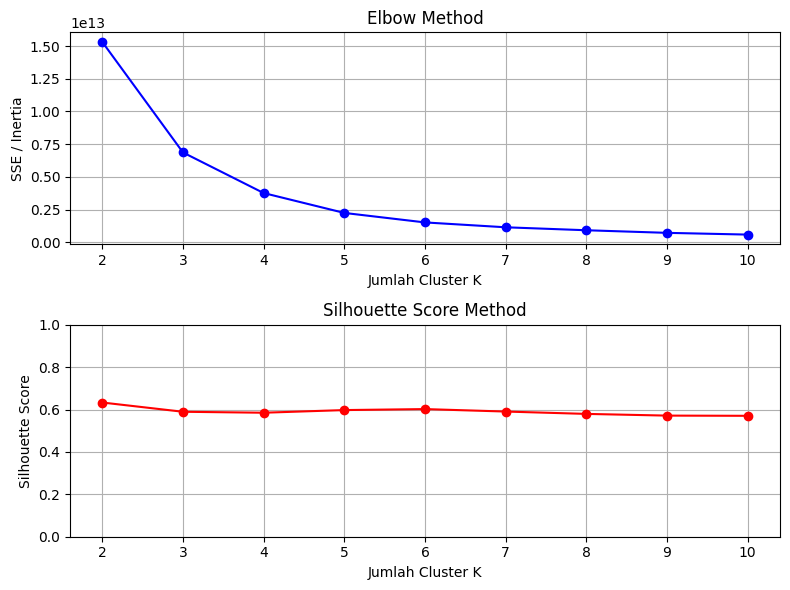

=== HASIL SKOR ===
K = 2 | Silhouette Score = 0.633
K = 3 | Silhouette Score = 0.590
K = 4 | Silhouette Score = 0.585
K = 5 | Silhouette Score = 0.598
K = 6 | Silhouette Score = 0.602
K = 7 | Silhouette Score = 0.591
K = 8 | Silhouette Score = 0.580
K = 9 | Silhouette Score = 0.572
K = 10 | Silhouette Score = 0.571


In [6]:
#Buat Grafik Silhoutte_Score
from sklearn.metrics import silhouette_score

# 2. LOOPING K = 1 SAMPE 10
inertia = [] # Buat Elbow / SSE
silhouette_scores = [] # Buat Silhouette
K_range = range(2, 11) # Silhouette minimal K=2

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)

    inertia.append(kmeans.inertia_) # Ambil SSE
    silhouette_scores.append(silhouette_score(X, kmeans.labels_)) # Ambil Silhouette

# 3. PLOT 2 GRAFIK
fig, ax = plt.subplots(2, 1, figsize=(8,6))

# GRAFIK 1: ELBOW METHOD
ax[0].plot(K_range, inertia, 'bo-')
ax[0].set_xlabel('Jumlah Cluster K')
ax[0].set_ylabel('SSE / Inertia')
ax[0].set_title('Elbow Method')
ax[0].grid(True)

# GRAFIK 2: SILHOUETTE SCORE
ax[1].plot(K_range, silhouette_scores, 'ro-')
ax[1].set_xlabel('Jumlah Cluster K')
ax[1].set_ylabel('Silhouette Score')
ax[1].set_title('Silhouette Score Method')
ax[1].grid(True)
ax[1].set_ylim([0, 1]) # Biar skalanya 0-1

plt.tight_layout()
plt.show()

# 4. CETAK SKOR BIAR GAMPANG BACANYA
print("=== HASIL SKOR ===")
for k, score in zip(K_range, silhouette_scores):
    print(f'K = {k} | Silhouette Score = {score:.3f}')

### Hasil Metode Elbow: 2 Segmen Pelanggan Utama



In [7]:
#K-Means clustering dengan k=2
kmeans = KMeans(n_clusters=2, random_state=42)
df['Cluster'] = kmeans.fit_predict(X)

In [8]:
cluster_map = {
    0: 'Cluster 1',
    1: 'Cluster 2'
}
df['Loyalty'] = df['Cluster'].map(cluster_map)

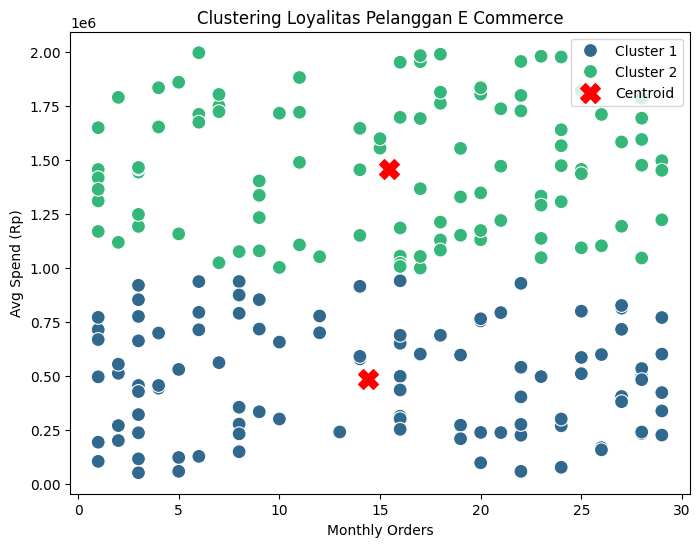

In [9]:
plt.figure(figsize=(8,6))
viridis_palette = sns.color_palette("viridis", n_colors=2)
sns.scatterplot(x='Monthly Orders', y='Avg Spend (Rp)',
                hue='Cluster', data=df, palette= viridis_palette, s=100)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
           c='red', marker='X', s=200, label='Centroid')
plt.title("Clustering Loyalitas Pelanggan E Commerce")
handles, labels = plt.gca().get_legend_handles_labels()
order = [0, 1, 2]
plt.legend([handles[i] for i in order],
          ['Cluster 1','Cluster 2','Centroid'])
#plt.legend()
plt.show()

In [10]:
summary = df.groupby('Loyalty').agg({
    'Monthly Orders':'mean',
    'Avg Spend (Rp)':'mean',
    'Age':'mean'
}).reset_index()
print(summary)

     Loyalty  Monthly Orders  Avg Spend (Rp)        Age
0  Cluster 1       14.404040    4.880755e+05  37.727273
1  Cluster 2       15.465347    1.458874e+06  39.584158


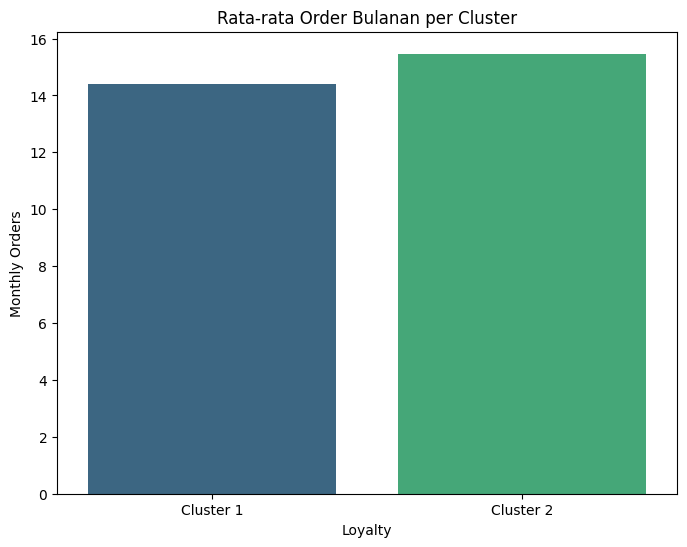

In [11]:
#Bar Chart Rata Rata order Bulanan per Cluster
plt.figure(figsize=(8,6))
sns.barplot(x='Loyalty', y='Monthly Orders',hue ='Loyalty',data=summary, palette='viridis')
plt.title("Rata-rata Order Bulanan per Cluster")
plt.show()

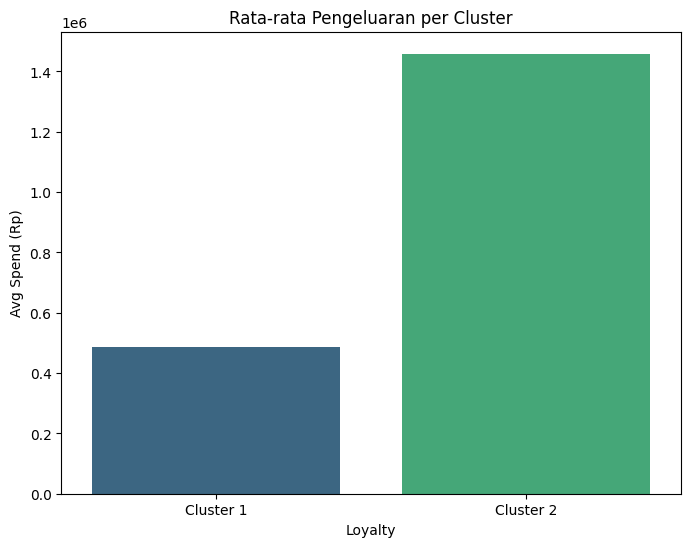

In [12]:
#Bar Chart Rata Rata Pengeluaran per Cluster
plt.figure(figsize=(8,6))
sns.barplot(x='Loyalty', y='Avg Spend (Rp)', hue= 'Loyalty',data=summary, palette='viridis')
plt.title("Rata-rata Pengeluaran per Cluster")
plt.show()